# Avance 5 · Ensambles homogéneos para reconstruir tiempos de viaje
**Equipo 42 | Proyecto Route Intelligence**

**Pregunta experimental.** ¿Promediar modelos de una misma familia permite reconstruir mejor los tiempos de viaje de la red que los modelos individuales del Avance 4, usando únicamente 32 consultas guía por instante?

Este cuaderno desarrolla el componente **homogéneo** del trabajo en equipo: bagging de árboles, Random Forest, Extra Trees y bagging de Ridge. Incluye búsqueda acotada de hiperparámetros, comparación con los seis modelos individuales de la fase anterior, tiempos medidos, diagnóstico gráfico y una recomendación vinculada al objetivo de negocio.

**Alcance:** reconstrucción contemporánea sobre una red experimental derivada de PEMS-BAY. Las consultas guía se simulan con el mismo estado de la red. No se está haciendo pronóstico futuro ni evaluando consultas reales de un proveedor. Los tiempos OD de referencia también se derivan de la red; no son mediciones independientes de viajes de vehículos.

## 1. Qué se mantiene y qué se contrasta

Se conserva el protocolo del [Avance 4 compartido](https://github.com/Luis-MX/route-intelligence/blob/main/docs/entregas/avance-4-modelos-alternativos/Avance4_Equipo42.ipynb): 322 nodos, 345 aristas, 32 consultas guía seleccionadas con enero–marzo y dos grupos disjuntos de 20 nodos de evaluación, con semilla 42. En cada instante se evalúan 760 pares OD dirigidos; para cada mes se toman 120 posiciones uniformemente distribuidas: **91,200 reconstrucciones OD**. Se excluye la diagonal y no se incluyen viajes entre los dos grupos.

| Etapa | Ajuste de referencias y modelos | Evaluación | Decisiones |
|---|---|---|---|
| Desarrollo | Enero–marzo de 2017 | Abril, 120 instantes | Configuración por familia y candidato final |
| Comparación posterior | Enero–abril de 2017 | Mayo, 120 instantes | Reportar desempeño; no cambiar hiperparámetros |
| Fuera del experimento | — | Junio | No se usa aquí |

**Métrica principal:** MAE OD en segundos, después de reconstruir las aristas y calcular caminos mínimos con Dijkstra. RMSE, WAPE, P95, sesgo y subestimaciones complementan el promedio. El error por arista no determina la selección.

**Regla previa a mayo:** elegir el menor MAE de abril entre los modelos individuales y las mejores configuraciones homogéneas. Los tiempos y el riesgo de subestimación se reportan para valorar la viabilidad, pero no se inventa una función de costo empresarial sin información de ventanas, penalizaciones o presupuesto de cómputo.

**Independencia limitada:** abril ya intervino en el Avance 4 y mayo fue examinado en los trabajos previos. Mayo es una comparación temporal posterior, no una prueba inédita de todo el proyecto. Junio tampoco debe presentarse como totalmente nuevo para el equipo. No se usan particiones aleatorias para seleccionar modelos; el bootstrap interno de bagging es un mecanismo de entrenamiento, no una validación temporal.

In [1]:
from pathlib import Path
import os, sys, json, time, platform, hashlib, warnings, gc
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 4
# Limitar BLAS evita que cada trabajador abra más hilos de los necesarios.
blas_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi': 125, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 180)
HERE = Path.cwd()
OUT = HERE / 'resultados'
OUT.mkdir(exist_ok=True)
versions = {p: metadata.version(p) for p in
            ['numpy','pandas','scipy','scikit-learn','matplotlib','pyarrow','nbformat','nbclient','ipykernel','threadpoolctl']}
print('Python:', sys.version.split()[0], '| Plataforma:', platform.platform())
print('Hilos de modelos:', N_JOBS, '| BLAS: 1')
display(pd.Series(versions, name='Versión').to_frame())

Python: 3.14.2 | Plataforma: macOS-26.7.1-arm64-arm-64bit-Mach-O
Hilos de modelos: 4 | BLAS: 1


,Versión
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
pyarrow,26.0.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
threadpoolctl,3.7.0


### Archivos y controles
El cuaderno es autónomo: no ejecuta celdas de otros notebooks ni requiere Google Drive. Para volver a ejecutarlo, colocar `routing_dataset_v1` junto a él o definir `ROUTE_INTELLIGENCE_DATASET_DIR`. Las salidas ya están incorporadas y pueden leerse sin entrenar de nuevo. El paquete de entrega incluye datos y versiones del entorno.

In [2]:
candidates = [Path(os.environ.get('ROUTE_INTELLIGENCE_DATASET_DIR', 'routing_dataset_v1')),
              HERE / 'routing_dataset_v1', HERE / 'data' / 'routing_dataset_v1']
required = ['nodes.csv','edges.csv','edge_travel_times.parquet','manifest.json']
DATA = next((p for p in candidates if all((p/f).is_file() for f in required)), None)
if DATA is None:
    raise FileNotFoundError('Coloque routing_dataset_v1 junto al notebook o defina ROUTE_INTELLIGENCE_DATASET_DIR.')
nodes = pd.read_csv(DATA/'nodes.csv', dtype={'node_id':str})
edges = pd.read_csv(DATA/'edges.csv', dtype={'edge_id':str,'from':str,'to':str})
et = pd.read_parquet(DATA/'edge_travel_times.parquet')
et.index = pd.to_datetime(et.index)
manifest = json.loads((DATA/'manifest.json').read_text())
assert et.shape == (52116,345)
assert len(nodes)==322 and len(edges)==345
assert et.columns.tolist()==edges.edge_id.tolist()
assert et.index.is_unique and et.index.is_monotonic_increasing
assert np.isfinite(et.to_numpy()).all() and (et.to_numpy()>0).all()
assert not edges.duplicated(['from','to']).any()
# Junio no participa ni en referencias históricas ni en generación de consultas.
et = et.loc[:'2017-05-31 23:59:59'].copy()
hashes = {f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in required}
print('Datos analizados:', et.shape, '|', et.index.min(), 'a', et.index.max())
print('Unidad original:', manifest['temporal_data']['travel_time_unit'])
print('SHA-256 de insumos:')
display(pd.Series(hashes).to_frame('SHA-256'))
print('Tipos de arista:', edges.edge_type.value_counts().to_dict())

Datos analizados: (43476, 345) | 2017-01-01 00:00:00 a 2017-05-31 23:55:00
Unidad original: minutes
SHA-256 de insumos:


,SHA-256
nodes.csv,d561fdb67e8cdf0be5f3d670f75578e4f5a1eddc65b6f6...
edges.csv,4f7cc9e5bd990c6b44f461b8f83dfdca220148681d7247...
edge_travel_times.parquet,ad7e9ffc5fb04f75862c2a5198b17aa5c628050ba82c17...
manifest.json,1e78be132e328a1c7fb04301e44d96050591d7a36df55d...


Tipos de arista: {'corridor': 273, 'sensor_to_interchange': 36, 'interchange_to_sensor': 36}


## 2. Construir las observaciones sin depender de archivos derivados

La entrada de cada modelo es la desviación relativa de las 32 consultas respecto de su mediana histórica. La salida contiene las desviaciones relativas de las 345 aristas:

\[x_{q,t}=OD_{q,t}/b^{OD}_{q,t}-1,\qquad y_{e,t}=T_{e,t}/b^{edge}_{e,t}-1.\]

Las referencias se ajustan por día de semana y posición de cinco minutos (2,016 grupos). Se calcula primero la ruta OD real de cada instante y luego su mediana histórica; **no se sustituye por el camino mínimo de las medianas de aristas**, pues esas operaciones no son equivalentes. La selección greedy maximiza cobertura de correlación al cuadrado usando únicamente enero–marzo. Se vuelve a calcular y se verifica contra las 32 consultas registradas en las salidas del notebook heterogéneo.

In [ ]:
node_idx = {n:i for i,n in enumerate(nodes.node_id)}
u = edges['from'].map(node_idx).to_numpy(dtype=int)
v = edges['to'].map(node_idx).to_numpy(dtype=int)
macro = sorted(nodes.loc[nodes.node_type=='interchange','node_id'].tolist())
macro_idx = np.array([node_idx[n] for n in macro])
macro_mask = ~np.eye(13,dtype=bool)
od_cols = [f'{a}__{b}' for a in macro for b in macro if a!=b]

def od_matrix(weights, target):
    assert np.isfinite(weights).all() and (weights>0).all()
    g = csr_matrix((weights,(u,v)),shape=(len(nodes),len(nodes)))
    return dijkstra(g,directed=True,indices=target)[:,target]

t0=time.perf_counter()
od_values = np.empty((len(et),156))
for i,row in enumerate(et.to_numpy(dtype=float)):
    od_values[i] = od_matrix(row,macro_idx)[macro_mask]
    if (i+1)%10000==0:
        print(f'Consultas OD construidas: {i+1:,}/{len(et):,}', flush=True)
od = pd.DataFrame(od_values,index=et.index,columns=od_cols)
assert np.isfinite(od_values).all() and (od_values>0).all()
print(f'Preparación OD: {time.perf_counter()-t0:.2f} s')

def keys(index):
    return pd.MultiIndex.from_arrays([index.day_of_week,index.hour*12+index.minute//5],
                                    names=['weekday','slot5'])

def relative_data(frame, train_index, eval_index):
    ref=frame.loc[train_index].groupby(keys(train_index)).median()
    base_tr=ref.reindex(keys(train_index)).to_numpy()
    base_ev=ref.reindex(keys(eval_index)).to_numpy()
    assert np.isfinite(base_tr).all() and np.isfinite(base_ev).all()
    assert (base_tr>0).all() and (base_ev>0).all()
    return frame.loc[train_index].to_numpy()/base_tr-1, frame.loc[eval_index].to_numpy()/base_ev-1, base_ev

idx_tr=et.loc[:'2017-03-31 23:59:59'].index
idx_ap=et.loc['2017-04'].index
Xall,Xapall,_=relative_data(od,idx_tr,idx_ap)
Ytr,Yap,base_ap=relative_data(et,idx_tr,idx_ap)
valid_edges=Ytr.std(axis=0,ddof=1)>1e-9
valid_queries=Xall.std(axis=0,ddof=1)>1e-9

def zscore(a):
    return np.asarray((a-a.mean(axis=0))/a.std(axis=0,ddof=1),dtype=np.float32)

corr=np.clip(zscore(Xall[:,valid_queries]).T @ zscore(Ytr[:,valid_edges])/(len(idx_tr)-1),-1,1)
r2=corr.astype(np.float64)**2
coverage=np.zeros(valid_edges.sum()); available=np.ones(valid_queries.sum(),dtype=bool)
selected=[]; ranking=[]
for k in range(32):
    new=np.maximum(coverage[None,:],r2)
    gains=new.mean(axis=1)-coverage.mean(); gains[~available]=-np.inf
    j=int(gains.argmax()); selected.append(j); available[j]=False; coverage=new[j]
    ranking.append({'Orden':k+1,'Consulta':np.array(od_cols)[valid_queries][j],
                    'Ganancia marginal':gains[j],'Cobertura media R2':coverage.mean()})
query_names=np.array(od_cols)[valid_queries][selected].tolist()
expected_queries='I08__I05 I10__I08 I09__I10 I11__I10 I11__I07 I12__I01 I01__I05 I01__I12 I02__I03 I07__I09 I02__I06 I07__I00 I01__I02 I00__I07 I04__I03 I02__I01 I05__I01 I12__I03 I03__I04 I06__I00 I06__I02 I04__I10 I09__I07 I03__I12 I10__I12 I02__I11 I03__I02 I12__I10 I00__I11 I12__I11 I04__I09 I08__I07'.split()
assert query_names==expected_queries, 'La selección difiere de la registrada; revisar antes de comparar.'
assert valid_edges.sum()==340 and len(idx_tr)==25908 and len(idx_ap)==8640
Xtr=Xall[:,valid_queries][:,selected]
Xap=Xapall[:,valid_queries][:,selected]
pd.DataFrame(ranking).to_csv(OUT/'consultas_seleccionadas.csv',index=False)
display(pd.DataFrame(ranking).round(5))
print('Entradas:', Xtr.shape,'| Objetivos:',Ytr.shape)
print('Las 32 consultas coinciden exactamente con las del cuaderno heterogéneo.')

Consultas OD construidas: 10,000/43,476


Consultas OD construidas: 20,000/43,476


Consultas OD construidas: 30,000/43,476


Consultas OD construidas: 40,000/43,476


Preparación OD: 8.14 s


,Orden,Consulta,Ganancia marginal,Cobertura media R2
0,1,I08__I05,0.07652,0.07652
1,2,I10__I08,0.04072,0.11723
2,3,I09__I10,0.01864,0.13587
3,4,I11__I10,0.01737,0.15325
4,5,I11__I07,0.01603,0.16928
5,6,I12__I01,0.01539,0.18467
6,7,I01__I05,0.01513,0.19981
7,8,I01__I12,0.01377,0.21358
8,9,I02__I03,0.01357,0.22715
9,10,I07__I09,0.01203,0.23918


Entradas: (25908, 32) | Objetivos: (25908, 345)
Las 32 consultas coinciden exactamente con las del cuaderno heterogéneo.


In [ ]:
sensor_nodes=sorted(nodes.loc[nodes.node_type!='interchange','node_id'].tolist())
chosen=np.random.default_rng(SEED).choice(sensor_nodes,size=40,replace=False)
target=np.array([node_idx[n] for n in chosen])
mask20=~np.eye(20,dtype=bool)
assert len(set(chosen))==40

def flatten_groups(tensor):
    # Orden: instante, grupo y par; conserva agrupación temporal para diagnósticos.
    return np.concatenate([tensor[:,:20,:20][:,mask20],tensor[:,20:,20:][:,mask20]],axis=1)

def reference_od(actual):
    return flatten_groups(np.stack([od_matrix(row,target) for row in actual]))*60

def metrics(errors, truth):
    return {'MAE OD (s)':np.abs(errors).mean(),
            'RMSE OD (s)':np.sqrt(np.mean(errors**2)),
            'WAPE (%)':100*np.abs(errors).sum()/truth.sum(),
            'P95 OD (s)':np.percentile(np.abs(errors),95),
            'Sesgo (s)':errors.mean(),
            'Subestima (%)':100*np.mean(errors<0),
            'Déficit medio (s)':np.maximum(-errors,0).mean()}

def evaluate(pred_relative, baseline, actual, truth):
    raw=baseline*(1+pred_relative)
    safe=np.where(raw>0,raw,baseline)
    pred=reference_od(safe)
    err=pred-truth
    return {**metrics(err,truth),'MAE aristas (s)':60*np.abs(safe-actual).mean(),
            'Respaldo (%)':100*np.mean(raw<=0)},err,pred

pos_ap=np.linspace(0,len(idx_ap)-1,120,dtype=int)
actual_ap=et.loc[idx_ap].to_numpy()[pos_ap]
truth_ap=reference_od(actual_ap)
assert truth_ap.shape==(120,760)
print('Grupo A:',chosen[:20].tolist())
print('Grupo B:',chosen[20:].tolist())
print('Viajes por mes:',truth_ap.size)
(OUT/'protocolo.json').write_text(json.dumps({'seed':SEED,'consultas':query_names,
   'grupo_A':chosen[:20].tolist(),'grupo_B':chosen[20:].tolist(),
   'posiciones_abril':pos_ap.tolist(),'métrica_principal':'MAE OD (s)'},ensure_ascii=False,indent=2))

Grupo A: ['407152', '400174', '407207', '400400', '400122', '407323', '407331', '400178', '401163', '402285', '401811', '400168', '400995', '402281', '400911', '400236', '400485', '402287', '401440', '405701']
Grupo B: ['402367', '401457', '400916', '407190', '402373', '407177', '402371', '401464', '404640', '400353', '404462', '400822', '400665', '404444', '401942', '402057', '403404', '407711', '401014', '400160']
Viajes por mes: 91200


2395

## 3. Hipótesis de los ensambles y presupuesto de búsqueda

| Familia homogénea | Fuente de diversidad | Qué se prueba |
|---|---|---|
| Bagging de árboles | Remuestreo de observaciones con reemplazo | Reducir la variabilidad de un árbol |
| Random Forest | Bootstrap y subconjunto de variables en cada división | Reducir correlación entre árboles |
| Extra Trees | Umbrales aleatorios y subconjunto de variables | Aumentar diversidad mediante particiones aleatorias |
| Bagging de Ridge | Bootstrap de regresores Ridge con la misma configuración | Comprobar si promediar modelos lineales estables aporta valor |

Son estrategias homogéneas porque cada ensamble combina miembros de una misma familia. Random Forest y Extra Trees son variantes de ensambles de árboles; **no representan familias tan distintas como combinar Ridge, KNN y MLP**. Se estudian estrategias de promedio; no se afirma haber cubierto boosting. No se hace stacking ni blending en esta contribución.

Se evalúan tres configuraciones por familia homogénea, variando tamaño, profundidad, hojas o intensidad del bootstrap. Se repite la rejilla del Avance 4 para Ridge (5 valores de alpha) y KNN (3 tamaños × 2 ponderaciones). Los demás modelos individuales conservan su configuración original. Es una **búsqueda acotada con un corte temporal**, no una optimización exhaustiva ni validación cruzada de varios orígenes. Todos los ajustes usan el conjunto completo de enero–marzo.

Los árboles comparten particiones entre las 345 salidas y minimizan error cuadrático de desviaciones relativas sin estandarizar los objetivos, coherente con el árbol del Avance 4. Eso puede favorecer aristas más variables y no optimiza directamente el MAE OD. El ajuste se decide por la evaluación OD externa de abril. No se utiliza el error OOB como sustituto de validación temporal.

In [5]:
class ConditionalPPCA(RegressorMixin, BaseEstimator):
    """Esperanza condicional de PPCA conjunta, como en el Avance 4."""
    def __init__(self,n_components=8,random_state=42):
        self.n_components=n_components; self.random_state=random_state
    def fit(self,X,y):
        self.n_features_in_=X.shape[1]
        self.scaler_=StandardScaler().fit(np.hstack([X,y]))
        z=self.scaler_.transform(np.hstack([X,y]))
        pca=PCA(n_components=self.n_components,svd_solver='randomized',random_state=self.random_state).fit(z)
        noise=max(float(pca.noise_variance_),1e-10)
        W=pca.components_.T*np.sqrt(np.maximum(pca.explained_variance_-noise,0))
        wx,wy=W[:self.n_features_in_],W[self.n_features_in_:]
        self.coef_=np.linalg.solve(wx@wx.T+noise*np.eye(self.n_features_in_),wx@wy.T)
        return self
    def predict(self,X):
        p=self.n_features_in_; s=self.scaler_
        return ((X-s.mean_[:p])/s.scale_[:p]@self.coef_)*s.scale_[p:]+s.mean_[p:]

specs=[]
def add(family,label,model,kind):
    specs.append({'Familia':family,'Configuración':label,'Modelo':model,'Tipo':kind})
for a in [.1,1,10,100,1000]:
    add('Ridge',f'alpha={a}',make_pipeline(StandardScaler(),Ridge(alpha=a)),'Individual')
for k in [5,15,30]:
    for w in ['uniform','distance']:
        add('KNN',f'k={k}; pesos={w}',make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=k,weights=w,n_jobs=N_JOBS)),'Individual')
add('Árbol','depth=10; leaf=50',DecisionTreeRegressor(max_depth=10,min_samples_leaf=50,random_state=SEED),'Individual')
add('PLS','componentes=5',PLSRegression(n_components=5,scale=True),'Individual')
add('MLP','32-16; alpha=0.001',TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(32,16),alpha=.001,batch_size=512,
                 learning_rate_init=.001,max_iter=120,tol=1e-4,n_iter_no_change=15,
                 early_stopping=False,random_state=SEED)),transformer=StandardScaler()),'Individual')
add('PPCA','componentes=8',ConditionalPPCA(),'Individual')
for n,depth,leaf in [(24,8,80),(48,10,50),(48,14,25)]:
    add('Bagging árboles',f'n={n}; depth={depth}; leaf={leaf}; sample=0.7',
        BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=depth,min_samples_leaf=leaf),
           n_estimators=n,max_samples=.7,bootstrap=True,n_jobs=N_JOBS,random_state=SEED),'Homogéneo')
for n,depth,leaf,feat in [(24,8,80,.5),(48,10,50,.7),(48,14,25,.7)]:
    add('Random Forest',f'n={n}; depth={depth}; leaf={leaf}; features={feat}',
        RandomForestRegressor(n_estimators=n,max_depth=depth,min_samples_leaf=leaf,
           max_features=feat,max_samples=.7,bootstrap=True,n_jobs=N_JOBS,random_state=SEED),'Homogéneo')
for n,depth,leaf,feat in [(24,8,80,.5),(48,10,50,.7),(48,14,25,1.)]:
    add('Extra Trees',f'n={n}; depth={depth}; leaf={leaf}; features={feat}',
        ExtraTreesRegressor(n_estimators=n,max_depth=depth,min_samples_leaf=leaf,
           max_features=feat,bootstrap=False,n_jobs=N_JOBS,random_state=SEED),'Homogéneo')
for n,a,sample in [(12,1000,.5),(24,1000,.8),(24,100,.8)]:
    add('Bagging Ridge',f'n={n}; alpha={a}; sample={sample}',
        BaggingRegressor(estimator=make_pipeline(StandardScaler(),Ridge(alpha=a)),
           n_estimators=n,max_samples=sample,bootstrap=True,n_jobs=N_JOBS,random_state=SEED),'Homogéneo')
print('Ajustes previstos:',len(specs),'| Homogéneos:',sum(s['Tipo']=='Homogéneo' for s in specs))

Ajustes previstos: 27 | Homogéneos: 12


In [6]:
tuning=[]
for i,s in enumerate(specs):
    model=clone(s['Modelo'])
    start=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(Xtr,Ytr)
    fit_s=time.perf_counter()-start
    start=time.perf_counter(); pred=model.predict(Xap[pos_ap]); infer_s=time.perf_counter()-start
    m,_,_=evaluate(pred,base_ap[pos_ap],actual_ap,truth_ap)
    tuning.append({'ID':i,'Familia':s['Familia'],'Tipo':s['Tipo'],
        'Configuración':s['Configuración'],**m,'Ajuste (s)':fit_s,'Inferencia (s)':infer_s,
        'Avisos':' | '.join(sorted(set(str(w.message) for w in caught)))})
    print(f"{i+1:02}/{len(specs)} {s['Familia']} | {s['Configuración']} | MAE OD={m['MAE OD (s)']:.4f} s | ajuste={fit_s:.2f} s",flush=True)
    del model; gc.collect()
tuning=pd.DataFrame(tuning)
tuning.to_csv(OUT/'busqueda_abril.csv',index=False)
best=tuning.sort_values(['MAE OD (s)','Ajuste (s)']).drop_duplicates('Familia')
selected_id=int(best.iloc[0]['ID'])
best_ensemble_id=int(best.loc[best.Tipo=='Homogéneo'].iloc[0]['ID'])
selected_family=specs[selected_id]['Familia']
ensemble_family=specs[best_ensemble_id]['Familia']
print('Mejor configuración por familia, ordenada por MAE:')
display(best[['Familia','Tipo','Configuración','MAE OD (s)','RMSE OD (s)','P95 OD (s)','Ajuste (s)']].round(4))
print('CANDIDATO FIJADO ANTES DE EVALUAR MAYO:', selected_family)
print('Mejor ensamble de abril:',ensemble_family)
print('Costo total búsqueda (ajustes):',round(tuning['Ajuste (s)'].sum(),2),'s')
if (tuning.Avisos!='').any():
    print('Avisos de ajuste, conservados para revisar convergencia:')
    display(tuning.loc[tuning.Avisos!='',['Familia','Avisos']])

01/27 Ridge | alpha=0.1 | MAE OD=9.6153 s | ajuste=0.02 s


02/27 Ridge | alpha=1 | MAE OD=9.6150 s | ajuste=0.01 s


03/27 Ridge | alpha=10 | MAE OD=9.6124 s | ajuste=0.01 s


04/27 Ridge | alpha=100 | MAE OD=9.5876 s | ajuste=0.01 s


05/27 Ridge | alpha=1000 | MAE OD=9.4479 s | ajuste=0.01 s


06/27 KNN | k=5; pesos=uniform | MAE OD=15.5464 s | ajuste=0.00 s


... (21 outputs left out)

Mejor configuración por familia, ordenada por MAE:


,Familia,Tipo,Configuración,MAE OD (s),RMSE OD (s),P95 OD (s),Ajuste (s)
25,Bagging Ridge,Homogéneo,n=24; alpha=1000; sample=0.8,9.4382,24.7283,37.4135,0.2941
4,Ridge,Individual,alpha=1000,9.4479,24.7112,37.5180,0.0118
8,KNN,Individual,k=15; pesos=distance,15.1819,37.9986,75.6796,0.0037
13,MLP,Individual,32-16; alpha=0.001,15.5282,37.6044,67.5716,4.2510
14,PPCA,Individual,componentes=8,17.2440,41.3794,76.2893,0.0855
12,PLS,Individual,componentes=5,17.5941,41.4408,77.4610,0.1782
17,Bagging árboles,Homogéneo,n=48; depth=14; leaf=25; sample=0.7,19.7791,47.0143,90.0202,33.1981
23,Extra Trees,Homogéneo,n=48; depth=14; leaf=25; features=1.0,19.8016,46.2813,90.8692,5.8347
20,Random Forest,Homogéneo,n=48; depth=14; leaf=25; features=0.7,20.1582,47.3483,93.4873,21.2360
11,Árbol,Individual,depth=10; leaf=50,23.9076,59.5147,112.9844,3.7320


CANDIDATO FIJADO ANTES DE EVALUAR MAYO: Bagging Ridge
Mejor ensamble de abril: Bagging Ridge
Costo total búsqueda (ajustes): 130.3 s
Avisos de ajuste, conservados para revisar convergencia:


,Familia,Avisos
13,MLP,Stochastic Optimizer: Maximum iterations (120)...


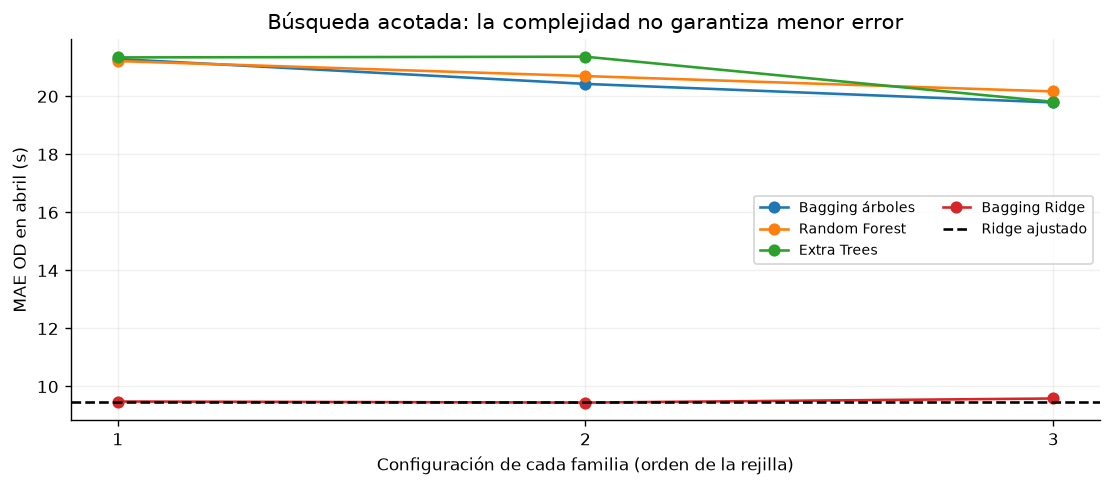

**Lectura.** El menor MAE de abril corresponde a **Bagging Ridge**; el mejor homogéneo es **Bagging Ridge**. Las configuraciones de la misma posición no tienen parámetros idénticos entre familias. El gráfico muestra sensibilidad a la rejilla, no una curva universal de escalabilidad ni evidencia de significancia.

In [7]:
fig,ax=plt.subplots(figsize=(9,4))
for fam,part in tuning.loc[tuning.Tipo=='Homogéneo'].groupby('Familia',sort=False):
    ax.plot(np.arange(1,len(part)+1),part['MAE OD (s)'],marker='o',label=fam)
ax.axhline(best.loc[best.Familia=='Ridge','MAE OD (s)'].iloc[0],color='black',ls='--',label='Ridge ajustado')
ax.set(xticks=[1,2,3],xlabel='Configuración de cada familia (orden de la rejilla)',
       ylabel='MAE OD en abril (s)',title='Búsqueda acotada: la complejidad no garantiza menor error')
ax.legend(ncol=2,fontsize=8); fig.tight_layout()
fig.savefig(OUT/'01_busqueda_abril.png',bbox_inches='tight'); plt.show()
display(Markdown(f"**Lectura.** El menor MAE de abril corresponde a **{selected_family}**; el mejor homogéneo es **{ensemble_family}**. Las configuraciones de la misma posición no tienen parámetros idénticos entre familias. El gráfico muestra sensibilidad a la rejilla, no una curva universal de escalabilidad ni evidencia de significancia."))

## 4. Reentrenamiento y comparación común en mayo

Las referencias históricas se recalculan con enero–abril y se mantiene la identidad de las 32 consultas. Se reentrena únicamente la configuración ganadora de abril de cada familia. El histórico K=0 sirve como referencia sin consultas. Los seis modelos individuales se vuelven a medir en este entorno; sus tiempos no se copian de otro equipo.

También se incluye Ridge con `alpha=1000` si no coincide con el Ridge seleccionado en abril, para cotejar el resultado de 11.5116 s comunicado en el notebook heterogéneo. El blending de 11.2710 s se cita únicamente como resultado externo del compañero, no como una ejecución de este cuaderno.

In [8]:
idx_full=et.loc[:'2017-04-30 23:59:59'].index
idx_may=et.loc['2017-05'].index
Xfull_all,Xmay_all,_=relative_data(od,idx_full,idx_may)
Yfull,Ymay,base_may=relative_data(et,idx_full,idx_may)
col_idx=[od.columns.get_loc(q) for q in query_names]
Xfull=Xfull_all[:,col_idx]; Xmay=Xmay_all[:,col_idx]
pos_may=np.linspace(0,len(idx_may)-1,120,dtype=int)
actual_may=et.loc[idx_may].to_numpy()[pos_may]
truth_may=reference_od(actual_may)
assert Xfull.shape==(34548,32) and Yfull.shape==(34548,345)
assert Xmay.shape==(8928,32) and truth_may.shape==(120,760)
assert idx_full.max()<idx_may.min()
print('Entrenamiento:',Xfull.shape,Yfull.shape,'| Evaluación:',len(pos_may),'instantes')
print('Mayo no determina la selección de hiperparámetros ni el candidato fijado.')

records=[]; fitted={}; errors={}; predictions={}; rel_predictions={}
# El tiempo histórico incluye el ajuste de las referencias edge y OD; se informa aparte.
t0=time.perf_counter()
_=et.loc[idx_full].groupby(keys(idx_full)).median()
_=od.loc[idx_full].groupby(keys(idx_full)).median()
historical_fit=time.perf_counter()-t0
m,e,p=evaluate(np.zeros_like(actual_may),base_may[pos_may],actual_may,truth_may)
records.append({'Modelo':'Histórico K=0','Tipo':'Referencia',**m,'Entrenamiento (s)':historical_fit,
                'Inferencia 120 (s)':0.,'Dijkstra y métricas (s)':np.nan})
errors['Histórico K=0']=e; predictions['Histórico K=0']=p
for _,row in best.iterrows():
    i=int(row.ID); s=specs[i]; name=s['Familia']; model=clone(s['Modelo'])
    start=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always'); model.fit(Xfull,Yfull)
    fit_s=time.perf_counter()-start
    start=time.perf_counter(); pred=model.predict(Xmay[pos_may]); infer_s=time.perf_counter()-start
    start=time.perf_counter(); m,e,p=evaluate(pred,base_may[pos_may],actual_may,truth_may)
    eval_s=time.perf_counter()-start
    fitted[name]=model; errors[name]=e; predictions[name]=p; rel_predictions[name]=pred
    records.append({'Modelo':name,'Tipo':s['Tipo'],**m,'Entrenamiento (s)':fit_s,
                    'Inferencia 120 (s)':infer_s,'Dijkstra y métricas (s)':eval_s})
    print(f"{name}: MAE OD={m['MAE OD (s)']:.4f} s; ajuste={fit_s:.2f} s; inferencia={infer_s:.3f} s",flush=True)
    for w in caught: print('  Aviso:',str(w.message))
comparison=pd.DataFrame(records).sort_values('MAE OD (s)').reset_index(drop=True)
comparison.to_csv(OUT/'comparativa_mayo.csv',index=False)
display(comparison.round(4))
print('Ajuste común de medianas históricas (edge + OD):',round(historical_fit,3),'s')
print('Los ajustes de modelos excluyen preparación OD, búsqueda y cálculo de medianas comunes.')
print('Histórico: inferencia relativa nula; el acceso a la tabla de medianas no se cronometra por separado.')

Entrenamiento: (34548, 32) (34548, 345) | Evaluación: 120 instantes
Mayo no determina la selección de hiperparámetros ni el candidato fijado.


Bagging Ridge: MAE OD=11.4853 s; ajuste=0.36 s; inferencia=0.013 s


Ridge: MAE OD=11.5116 s; ajuste=0.02 s; inferencia=0.000 s


KNN: MAE OD=18.5449 s; ajuste=0.00 s; inferencia=0.011 s


MLP: MAE OD=18.8033 s; ajuste=4.92 s; inferencia=0.000 s


PPCA: MAE OD=21.3450 s; ajuste=0.11 s; inferencia=0.000 s


... (3 outputs left out)

Random Forest: MAE OD=21.8136 s; ajuste=29.57 s; inferencia=0.014 s


Árbol: MAE OD=26.0678 s; ajuste=5.11 s; inferencia=0.000 s


,Modelo,Tipo,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),Sesgo (s),Subestima (%),Déficit medio (s),MAE aristas (s),Respaldo (%),Entrenamiento (s),Inferencia 120 (s),Dijkstra y métricas (s)
0,Bagging Ridge,Homogéneo,11.4853,28.5929,1.4380,51.9056,0.8419,36.9781,5.3217,1.6530,0.0169,0.3622,0.0133,0.0556
1,Ridge,Individual,11.5116,28.6870,1.4413,52.1676,0.8475,37.2390,5.3320,1.6579,0.0169,0.0158,0.0003,0.0559
2,KNN,Individual,18.5449,42.5826,2.3219,88.7587,-4.0544,54.5033,11.2996,1.6380,0.0000,0.0047,0.0115,0.0555
3,MLP,Individual,18.8033,41.2904,2.3543,86.2662,2.2143,47.4770,8.2945,1.9053,0.0048,4.9241,0.0004,0.0563
4,Extra Trees,Homogéneo,21.2290,49.1214,2.6580,92.0998,-1.1437,41.8553,11.1864,1.7243,0.0000,7.9394,0.0137,0.0572
5,PPCA,Individual,21.3450,48.7140,2.6725,92.4200,1.2337,35.6689,10.0557,1.8907,0.0048,0.1093,0.0001,0.0562
6,Random Forest,Homogéneo,21.8136,51.3106,2.7312,94.2340,-1.1970,42.6634,11.5053,1.7548,0.0000,29.5655,0.0137,0.0573
7,Bagging árboles,Homogéneo,22.1142,52.2056,2.7688,95.6058,-1.4154,42.7193,11.7648,1.7656,0.0000,46.8076,0.0262,0.0555
8,PLS,Individual,22.4824,50.8299,2.8149,96.8512,1.7770,37.6809,10.3527,1.9607,0.0024,0.2239,0.0002,0.0566
9,Árbol,Individual,26.0678,61.7501,3.2638,112.5502,-4.1390,40.3421,15.1034,1.9291,0.0000,5.1111,0.0002,0.0569


Ajuste común de medianas históricas (edge + OD): 0.196 s
Los ajustes de modelos excluyen preparación OD, búsqueda y cálculo de medianas comunes.
Histórico: inferencia relativa nula; el acceso a la tabla de medianas no se cronometra por separado.


Control Ridge alpha=1000: 11.511626 s; referencia del compañero: 11.5116 s
Coincidencia dentro de 0.005 s: True


**Resultado de la comparación.** El candidato fijado con abril, **Bagging Ridge**, obtiene **11.485 s** de MAE OD en mayo. El mejor homogéneo según abril, **Bagging Ridge**, alcanza **11.485 s**, frente a **11.512 s** de Ridge. Su reducción relativa frente a Ridge es **0.23%** (un valor negativo indica deterioro). Esta comparación no cambia la regla de selección original.

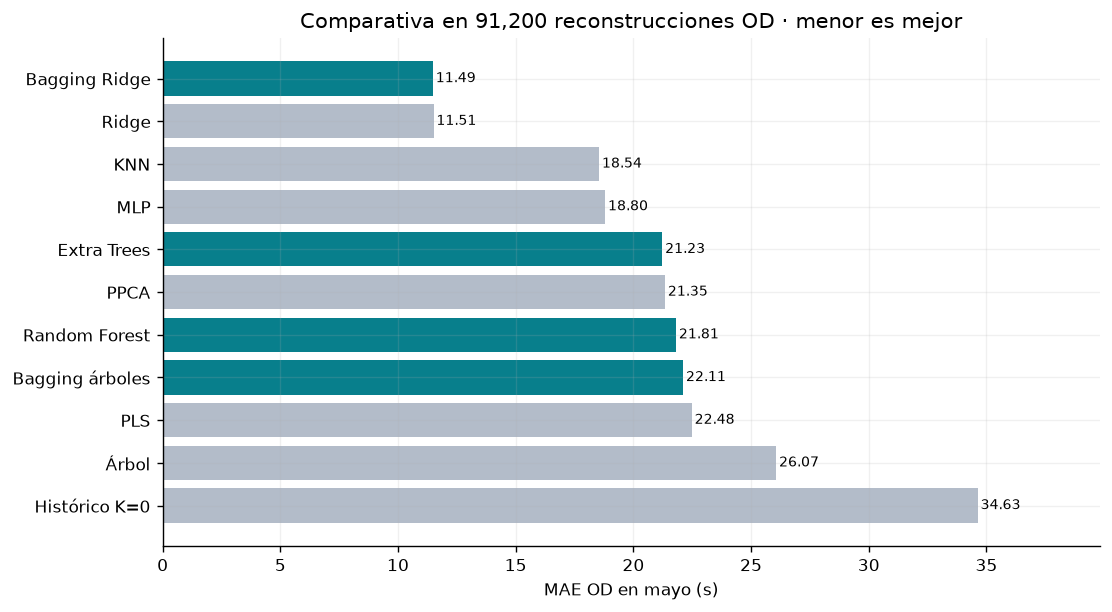

In [9]:
ridge_check=make_pipeline(StandardScaler(),Ridge(alpha=1000)).fit(Xfull,Yfull)
check,_,_=evaluate(ridge_check.predict(Xmay[pos_may]),base_may[pos_may],actual_may,truth_may)
print(f"Control Ridge alpha=1000: {check['MAE OD (s)']:.6f} s; referencia del compañero: 11.5116 s")
match=np.isclose(check['MAE OD (s)'],11.5116,atol=.005)
print('Coincidencia dentro de 0.005 s:',match)
assert match, 'Diferencia material con la referencia: revisar identidad del protocolo.'
selected_row=comparison.set_index('Modelo').loc[selected_family]
ensemble_row=comparison.set_index('Modelo').loc[ensemble_family]
ridge_row=comparison.set_index('Modelo').loc['Ridge']
gain=100*(ridge_row['MAE OD (s)']-ensemble_row['MAE OD (s)'])/ridge_row['MAE OD (s)']
display(Markdown(f"**Resultado de la comparación.** El candidato fijado con abril, **{selected_family}**, obtiene **{selected_row['MAE OD (s)']:.3f} s** de MAE OD en mayo. El mejor homogéneo según abril, **{ensemble_family}**, alcanza **{ensemble_row['MAE OD (s)']:.3f} s**, frente a **{ridge_row['MAE OD (s)']:.3f} s** de Ridge. Su reducción relativa frente a Ridge es **{gain:.2f}%** (un valor negativo indica deterioro). Esta comparación no cambia la regla de selección original."))
fig,ax=plt.subplots(figsize=(9,5))
view=comparison.sort_values('MAE OD (s)',ascending=False)
ax.barh(view.Modelo,view['MAE OD (s)'],color=['#087f8c' if x=='Homogéneo' else '#b3bcc9' for x in view.Tipo])
ax.set(xlabel='MAE OD en mayo (s)',title='Comparativa en 91,200 reconstrucciones OD · menor es mejor')
for j,value in enumerate(view['MAE OD (s)']): ax.text(value+.12,j,f'{value:.2f}',va='center',fontsize=8)
ax.set_xlim(0,view['MAE OD (s)'].max()*1.15)
fig.tight_layout(); fig.savefig(OUT/'02_comparativa_mayo.png',bbox_inches='tight'); plt.show()

## 5. Diagnóstico del candidato y del mejor homogéneo

El residuo se define como **estimado menos referencia**: valores negativos son subestimaciones. Se analiza el candidato fijado en abril y, si es distinto, el mejor homogéneo. Los gráficos describen el comportamiento en mayo; no se usan para volver a seleccionar modelos. Al ser una regresión continua, ROC y matriz de confusión no son las herramientas adecuadas sin definir previamente un evento de clasificación.

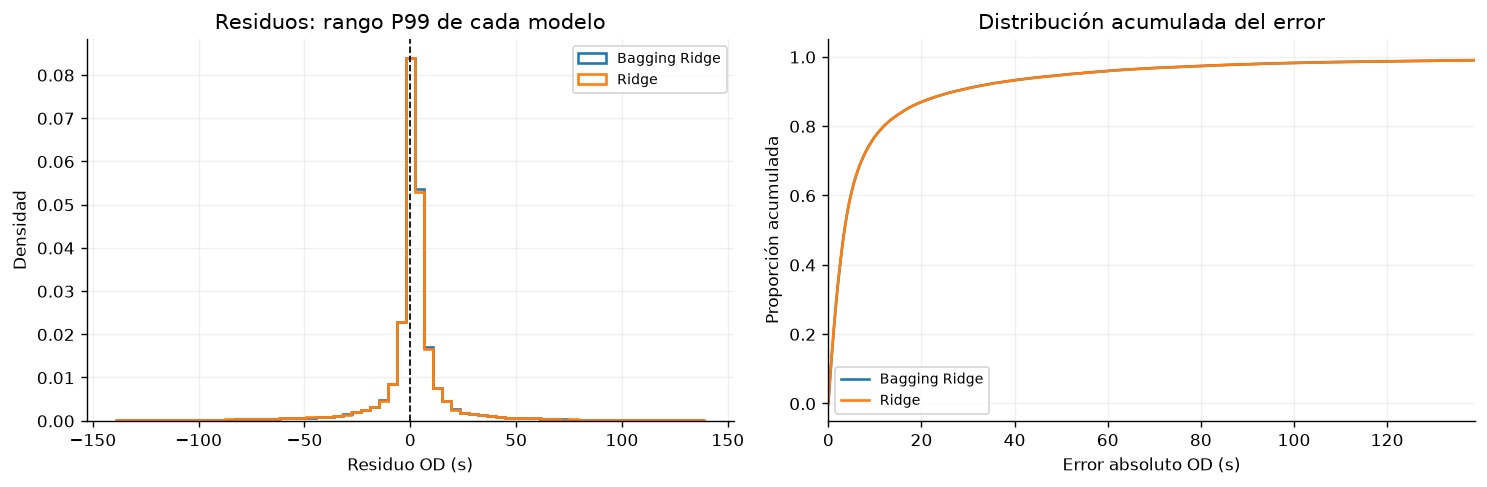

**Interpretación.** Bagging Ridge presenta sesgo medio de **0.842 s** y P95 absoluto de **51.906 s**. La curva acumulada más alta a una tolerancia dada representa más viajes dentro de ese error. Las colas fuera del rango visual sí se incluyen en las métricas; un sesgo cercano a cero podría ocultar compensación entre sobreestimaciones y subestimaciones.

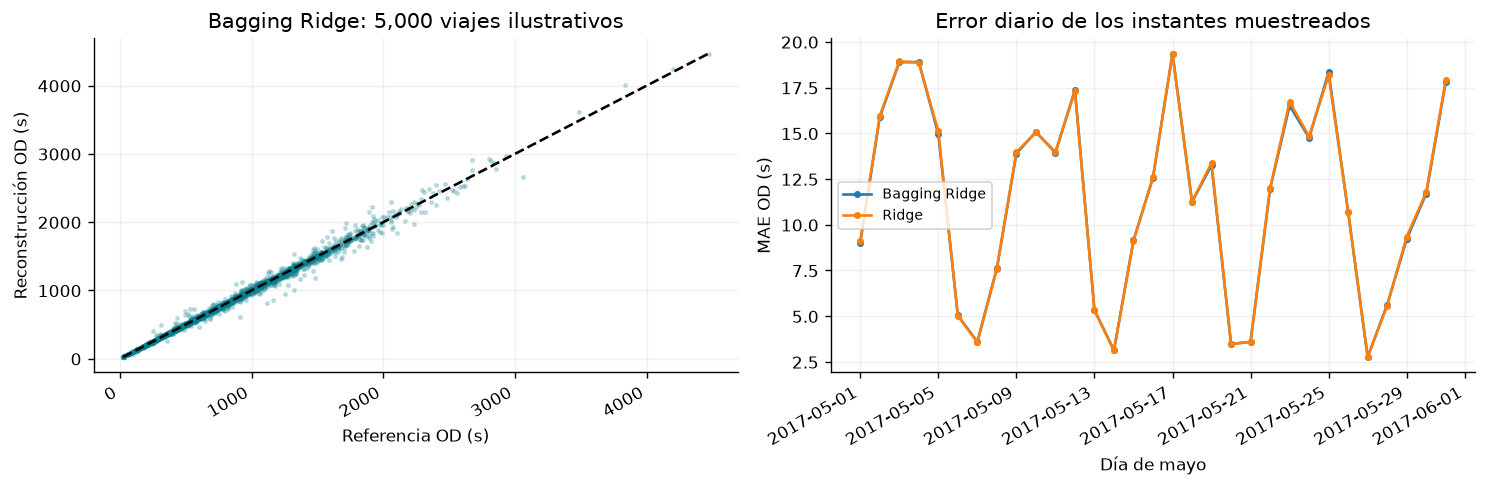

**Interpretación.** La diagonal indica reconstrucción exacta y la dispersión muestra errores en tiempos absolutos. El mayor MAE diario observado del candidato ocurre el **17/05/2017**. Se trata de los puntos muestreados de cada día, no del error de todos sus intervalos; el gráfico no demuestra que un incidente haya causado ese pico.

In [10]:
diagnostic_names=list(dict.fromkeys([selected_family,ensemble_family,'Ridge']))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name in diagnostic_names:
    e=errors[name].ravel()
    lim=np.percentile(np.abs(e),99)
    axs[0].hist(e,bins=65,range=(-lim,lim),density=True,histtype='step',lw=1.5,label=name)
    vals=np.sort(np.abs(e))
    axs[1].plot(vals,np.arange(1,len(vals)+1)/len(vals),label=name)
axs[0].axvline(0,color='black',ls='--',lw=1)
axs[0].set(xlabel='Residuo OD (s)',ylabel='Densidad',title='Residuos: rango P99 de cada modelo')
axs[1].set(xlim=(0,max(np.percentile(np.abs(errors[n]),99) for n in diagnostic_names)),
           xlabel='Error absoluto OD (s)',ylabel='Proporción acumulada',title='Distribución acumulada del error')
for ax in axs: ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'03_residuos_distribucion.png',bbox_inches='tight');plt.show()
selected_err=errors[selected_family]
display(Markdown(f"**Interpretación.** {selected_family} presenta sesgo medio de **{selected_err.mean():.3f} s** y P95 absoluto de **{np.percentile(np.abs(selected_err),95):.3f} s**. La curva acumulada más alta a una tolerancia dada representa más viajes dentro de ese error. Las colas fuera del rango visual sí se incluyen en las métricas; un sesgo cercano a cero podría ocultar compensación entre sobreestimaciones y subestimaciones."))

fig,axs=plt.subplots(1,2,figsize=(12,4))
rng=np.random.default_rng(SEED); sub=rng.choice(truth_may.size,5000,replace=False)
xx=truth_may.ravel()[sub]; yy=predictions[selected_family].ravel()[sub]
axs[0].scatter(xx,yy,s=4,alpha=.2,c='#087f8c')
lo,hi=min(xx.min(),yy.min()),max(xx.max(),yy.max())
axs[0].plot([lo,hi],[lo,hi],c='black',ls='--')
axs[0].set(xlabel='Referencia OD (s)',ylabel='Reconstrucción OD (s)',title=f'{selected_family}: 5,000 viajes ilustrativos')
for name in diagnostic_names:
    daily=pd.Series(np.abs(errors[name]).mean(axis=1),index=idx_may[pos_may]).groupby(idx_may[pos_may].normalize()).mean()
    axs[1].plot(daily.index,daily.values,marker='.',label=name)
axs[1].set(xlabel='Día de mayo',ylabel='MAE OD (s)',title='Error diario de los instantes muestreados')
axs[1].legend(fontsize=8);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUT/'04_ajuste_y_tiempo.png',bbox_inches='tight');plt.show()
worst=pd.Series(np.abs(selected_err).mean(axis=1),index=idx_may[pos_may]).groupby(idx_may[pos_may].normalize()).mean().idxmax()
display(Markdown(f"**Interpretación.** La diagonal indica reconstrucción exacta y la dispersión muestra errores en tiempos absolutos. El mayor MAE diario observado del candidato ocurre el **{worst:%d/%m/%Y}**. Se trata de los puntos muestreados de cada día, no del error de todos sus intervalos; el gráfico no demuestra que un incidente haya causado ese pico."))

,Modelo,Subestima (%),Déficit medio (s),Subestima >30s (%),Subestima >60s (%),P95 absoluto (s)
0,Bagging Ridge,36.9781,5.3217,4.6140,2.1721,51.9056
1,Ridge,37.2390,5.3320,4.6382,2.1776,52.1676


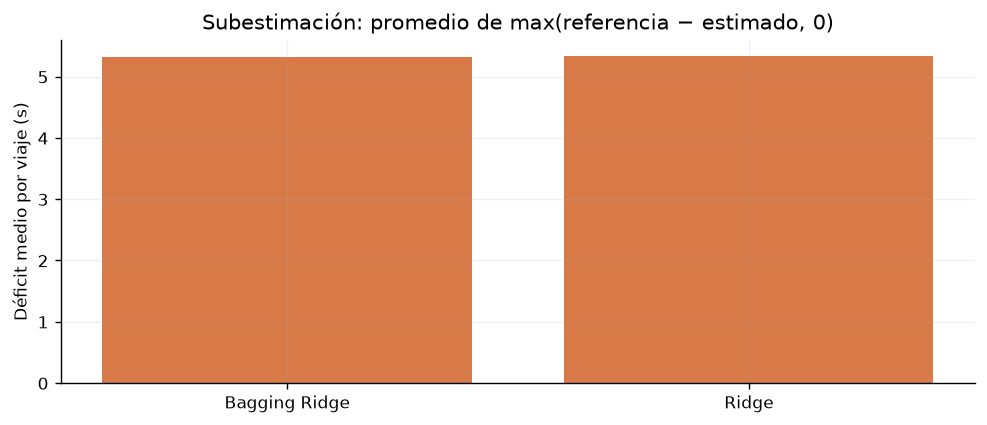

**Interpretación.** El déficit incluye ceros cuando no hay subestimación y evita confundir una media condicionada con el riesgo global. Menor MAE no implica menor déficit. Sin simular ventanas de servicio, estos indicadores son aproximaciones del riesgo y no demuestran ahorros o mayor cumplimiento logístico.

In [11]:
# Riesgo de indicar duraciones demasiado bajas, sobre todos los viajes.
risk=[]
for name in diagnostic_names:
    e=errors[name]
    risk.append({'Modelo':name,'Subestima (%)':100*(e<0).mean(),
                 'Déficit medio (s)':np.maximum(-e,0).mean(),
                 'Subestima >30s (%)':100*(e < -30).mean(),
                 'Subestima >60s (%)':100*(e < -60).mean(),
                 'P95 absoluto (s)':np.percentile(np.abs(e),95)})
risk=pd.DataFrame(risk)
display(risk.round(4));risk.to_csv(OUT/'riesgo_subestimacion.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.bar(risk.Modelo,risk['Déficit medio (s)'],color='#d87948')
ax.set(ylabel='Déficit medio por viaje (s)',title='Subestimación: promedio de max(referencia − estimado, 0)')
fig.tight_layout();fig.savefig(OUT/'05_subestimacion.png',bbox_inches='tight');plt.show()
display(Markdown('**Interpretación.** El déficit incluye ceros cuando no hay subestimación y evita confundir una media condicionada con el riesgo global. Menor MAE no implica menor déficit. Sin simular ventanas de servicio, estos indicadores son aproximaciones del riesgo y no demuestran ahorros o mayor cumplimiento logístico.'))

### Aporte de las consultas a la reconstrucción

Se calcula importancia por permutación usando el **MAE OD completo**, no el MSE de las aristas: para cada consulta se altera su orden en los 120 instantes de mayo, se reconstruye la red y se vuelve a evaluar. Dos repeticiones con semilla fija. Es un diagnóstico de sensibilidad del candidato, no una selección de variables ni un efecto causal. Las consultas correlacionadas pueden sustituirse y las combinaciones permutadas pueden ser poco realistas.

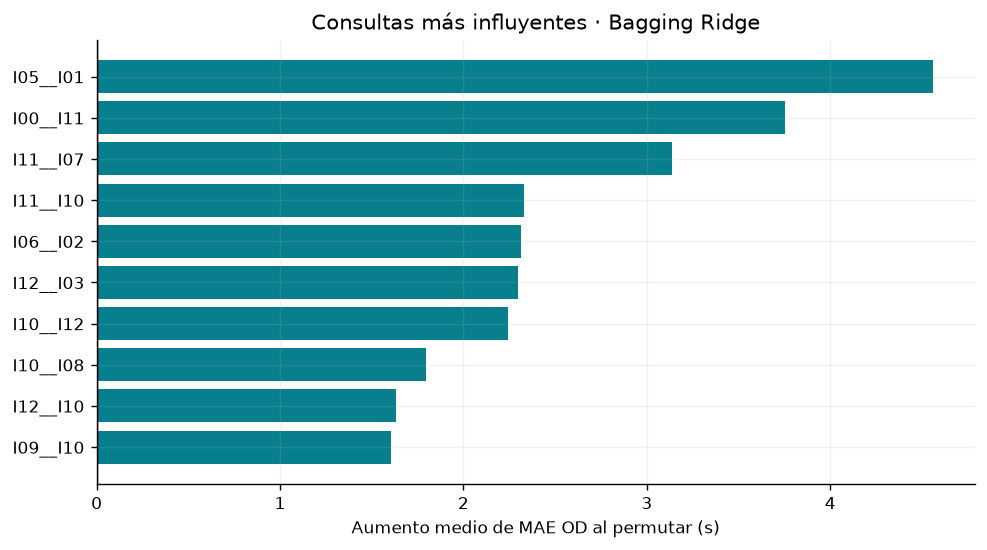

**Interpretación.** La mayor sensibilidad observada corresponde a **I05__I01**: permutar esa entrada incrementa el MAE en **4.561 s**. Este valor depende de las otras 31 consultas y de este mes. Dos repeticiones no proporcionan un intervalo de confianza estable.

In [12]:
rng=np.random.default_rng(SEED)
importance=[]
for j,q in enumerate(query_names):
    changes=[]
    for rep in range(2):
        xp=Xmay[pos_may].copy(); xp[:,j]=xp[rng.permutation(len(xp)),j]
        m,_,_=evaluate(fitted[selected_family].predict(xp),base_may[pos_may],actual_may,truth_may)
        changes.append(m['MAE OD (s)']-selected_row['MAE OD (s)'])
    importance.append({'Consulta':q,'Aumento MAE OD (s)':np.mean(changes),'Rango repeticiones (s)':np.ptp(changes)})
importance=pd.DataFrame(importance).sort_values('Aumento MAE OD (s)',ascending=False)
importance.to_csv(OUT/'importancia_permutacion_od.csv',index=False)
view=importance.head(10).sort_values('Aumento MAE OD (s)')
fig,ax=plt.subplots(figsize=(8,4.5))
ax.barh(view.Consulta,view['Aumento MAE OD (s)'],color='#087f8c')
ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Aumento medio de MAE OD al permutar (s)',title=f'Consultas más influyentes · {selected_family}')
fig.tight_layout();fig.savefig(OUT/'06_importancia_consultas.png',bbox_inches='tight');plt.show()
display(Markdown(f"**Interpretación.** La mayor sensibilidad observada corresponde a **{importance.iloc[0]['Consulta']}**: permutar esa entrada incrementa el MAE en **{importance.iloc[0]['Aumento MAE OD (s)']:.3f} s**. Este valor depende de las otras 31 consultas y de este mes. Dos repeticiones no proporcionan un intervalo de confianza estable."))

## 6. Estabilidad de la diferencia frente a Ridge

Los 91,200 viajes comparten red e instante y **no se tratan como observaciones independientes**. Se emparejan los errores por instante, se resumen por día y se remuestrean bloques circulares de tres días consecutivos. Cada remuestreo mantiene juntos los viajes de los instantes de cada día. Se muestran también bloques de uno y siete días como sensibilidad. El bloque de un día no preserva dependencia entre días.

Los intervalos son exploratorios: sólo hay 31 días, cuatro instantes aproximadamente por día y el mes ya fue consultado por el equipo. El remuestreo no incorpora incertidumbre del entrenamiento ni de la búsqueda, ni corrige selección de modelos. Una diferencia positiva favorece al homogéneo seleccionado en abril.

In [13]:
delta=np.abs(errors['Ridge']).mean(axis=1)-np.abs(errors[ensemble_family]).mean(axis=1)
daily=pd.Series(delta,index=idx_may[pos_may]).groupby(idx_may[pos_may].normalize()).agg(['sum','count'])
assert len(daily)==31

def block_bootstrap_daily(table,block,B=3000):
    rng=np.random.default_rng(SEED); n=len(table); vals=[]
    sums=table['sum'].to_numpy(); counts=table['count'].to_numpy()
    for _ in range(B):
        starts=rng.integers(0,n,size=int(np.ceil(n/block)))
        ids=((starts[:,None]+np.arange(block))%n).ravel()[:n]
        vals.append(sums[ids].sum()/counts[ids].sum())
    return np.percentile(vals,[2.5,97.5])
ci_rows=[]
for block in [1,3,7]:
    lo,hi=block_bootstrap_daily(daily,block)
    ci_rows.append({'Bloque (días)':block,'Reducción MAE (s)':delta.mean(),'IC95 inferior (s)':lo,'IC95 superior (s)':hi})
ci=pd.DataFrame(ci_rows);display(ci.round(4));ci.to_csv(OUT/'incertidumbre_exploratoria.csv',index=False)
print(f'Instantes con menor MAE del homogéneo: {100*np.mean(delta>0):.2f}%')
central=ci.loc[ci['Bloque (días)']==3].iloc[0]
conclusion_ci=('incluye cero; la mejora media no queda establecida' if central['IC95 inferior (s)']<=0<=central['IC95 superior (s)']
               else 'no incluye cero en este remuestreo exploratorio; esto no prueba generalización')
display(Markdown(f"**Lectura.** La reducción media de MAE de **{ensemble_family}** frente a Ridge es **{delta.mean():.4f} s**. El intervalo de bloques de tres días **{conclusion_ci}**. El cambio al variar el bloque informa sensibilidad a la dependencia temporal; no se interpreta como una prueba confirmatoria."))

,Bloque (días),Reducción MAE (s),IC95 inferior (s),IC95 superior (s)
0,1,0.0263,0.0018,0.0518
1,3,0.0263,0.0029,0.0502
2,7,0.0263,0.0033,0.0483


Instantes con menor MAE del homogéneo: 47.50%


**Lectura.** La reducción media de MAE de **Bagging Ridge** frente a Ridge es **0.0263 s**. El intervalo de bloques de tres días **no incluye cero en este remuestreo exploratorio; esto no prueba generalización**. El cambio al variar el bloque informa sensibilidad a la dependencia temporal; no se interpreta como una prueba confirmatoria.

### 6.1. ¿La ventaja de bagging de Ridge proviene del promedio?

Este control se añadió **después de observar la búsqueda de abril**, para interpretar el resultado de bagging de Ridge; es exploratorio y **no cambia el candidato fijado ni amplía la búsqueda principal de 27 configuraciones**.

Un bootstrap de tamaño $m$ usa menos observaciones que el ajuste completo de tamaño $N$. En Ridge, cuya penalización se suma a la suma de errores cuadrados, mantener el mismo `alpha` aumenta la regularización relativa. La función de pérdida esperada del bootstrap sugiere un control de datos completos con $\alpha_{control}=\alpha N/m$ (aproximadamente 1,250 para una fracción 0.8 y alpha 1,000).

**Esto no establece equivalencia de predicciones:** cada remuestreo tiene otras multiplicidades, covarianzas y escalado; promediar soluciones no equivale a minimizar la función esperada. El control sólo ayuda a separar una posible explicación por intensidad de regularización de una ventaja atribuida al promedio.

In [14]:
bag_row=tuning.loc[tuning.Familia=='Bagging Ridge'].sort_values('MAE OD (s)').iloc[0]
bag_spec=specs[int(bag_row.ID)]['Modelo']
base_alpha=bag_spec.estimator.named_steps['ridge'].alpha
ablation=[]
for period,xx,yy,xev,base,actual,truth in [
    ('Abril',Xtr,Ytr,Xap[pos_ap],base_ap[pos_ap],actual_ap,truth_ap),
    ('Mayo',Xfull,Yfull,Xmay[pos_may],base_may[pos_may],actual_may,truth_may)]:
    sample_size=int(bag_spec.max_samples*len(xx))
    alpha_control=base_alpha*len(xx)/sample_size
    controls=[('Ridge alpha=1000',make_pipeline(StandardScaler(),Ridge(alpha=1000))),
              ('Ridge regularización comparable',make_pipeline(StandardScaler(),Ridge(alpha=alpha_control))),
              ('Bagging Ridge',clone(bag_spec))]
    for name,model in controls:
        start=time.perf_counter();model.fit(xx,yy);fit_s=time.perf_counter()-start
        m,_,_=evaluate(model.predict(xev),base,actual,truth)
        ablation.append({'Mes':period,'Modelo':name,'Alpha base':base_alpha if name=='Bagging Ridge' else (1000 if name=='Ridge alpha=1000' else alpha_control),
                         'MAE OD (s)':m['MAE OD (s)'],'RMSE OD (s)':m['RMSE OD (s)'],'Ajuste control (s)':fit_s})
ablation=pd.DataFrame(ablation)
ablation.to_csv(OUT/'control_regularizacion.csv',index=False)
display(ablation.round(5))
for period in ['Abril','Mayo']:
    a=ablation.loc[ablation.Mes==period].set_index('Modelo')['MAE OD (s)']
    print(f"{period}: bagging − Ridge de regularización comparable = {a['Bagging Ridge']-a['Ridge regularización comparable']:+.5f} s (negativo favorece bagging).")
assert np.isclose(ablation.loc[(ablation.Mes=='Abril')&(ablation.Modelo=='Bagging Ridge'),'MAE OD (s)'].iloc[0],bag_row['MAE OD (s)'],atol=1e-6)
may=ablation.loc[ablation.Mes=='Mayo'].set_index('Modelo')['MAE OD (s)']
if may['Ridge regularización comparable'] <= may['Bagging Ridge']:
    finding='En mayo, Ridge con regularización comparable iguala o supera a bagging. No se puede atribuir al promedio una ventaja que también puede explicar la intensidad de la regularización.'
else:
    finding='En mayo, bagging conserva menor MAE que el control de regularización comparable. Esto es compatible con un aporte adicional del remuestreo y el promedio, pero este único contraste retrospectivo no lo demuestra por sí solo.'
display(Markdown('**Interpretación del control.** '+finding+' La elección original permanece fijada por abril. Para una decisión operativa, Ridge sigue siendo una alternativa de menor complejidad que debe contrastarse en nuevos periodos.'))

,Mes,Modelo,Alpha base,MAE OD (s),RMSE OD (s),Ajuste control (s)
0,Abril,Ridge alpha=1000,1000.00000,9.44789,24.71119,0.01477
1,Abril,Ridge regularización comparable,1250.02412,9.43971,24.71502,0.01144
2,Abril,Bagging Ridge,1000.00000,9.43822,24.72825,1.52284
3,Mayo,Ridge alpha=1000,1000.00000,11.51163,28.68696,0.02601
4,Mayo,Ridge regularización comparable,1250.01809,11.49664,28.60791,0.01459
5,Mayo,Bagging Ridge,1000.00000,11.48533,28.59289,0.34498


Abril: bagging − Ridge de regularización comparable = -0.00149 s (negativo favorece bagging).
Mayo: bagging − Ridge de regularización comparable = -0.01131 s (negativo favorece bagging).


**Interpretación del control.** En mayo, bagging conserva menor MAE que el control de regularización comparable. Esto es compatible con un aporte adicional del remuestreo y el promedio, pero este único contraste retrospectivo no lo demuestra por sí solo. La elección original permanece fijada por abril. Para una decisión operativa, Ridge sigue siendo una alternativa de menor complejidad que debe contrastarse en nuevos periodos.

## 7. Decisión para el componente homogéneo y límites de negocio

Los ensambles de árboles sí mejoran al árbol individual en mayo: Extra Trees reduce su MAE de **26.068 a 21.229 s** (18.56%), aunque sigue lejos de Ridge. Esto distingue una mejora respecto de su propio modelo base de una mejora respecto del mejor modelo del proyecto.

El control de regularización lleva Ridge de **11.5116 a 11.4966 s**; la ventaja restante de bagging frente a ese control es **0.0113 s**. Parte de la diferencia inicial se reproduce con una regularización individual más intensa. No se atribuye toda la ganancia al promedio.

La MLP alcanzó su límite de 120 iteraciones sin converger durante el desarrollo; se conserva para reproducir la configuración previa y se registra su aviso. La clasificación de resultados describe las configuraciones evaluadas, no el mejor desempeño posible de cada familia.

In [15]:
historical_mae=comparison.set_index('Modelo').loc['Histórico K=0','MAE OD (s)']
benefit=100*(historical_mae-selected_row['MAE OD (s)'])/historical_mae
if selected_family==ensemble_family:
    decision=f'Se propone **{selected_family}** como candidato homogéneo para la siguiente etapa, al haber sido seleccionado por MAE de abril.'
else:
    decision=f'La selección por abril favorece **{selected_family}** como referencia final de este experimento. **{ensemble_family}** se conserva como mejor candidato homogéneo, sin reemplazar automáticamente al modelo individual.'
display(Markdown(f"""{decision}

- **Precisión posterior:** el candidato alcanza MAE **{selected_row['MAE OD (s)']:.3f} s**, RMSE **{selected_row['RMSE OD (s)']:.3f} s** y P95 **{selected_row['P95 OD (s)']:.3f} s** en mayo. Frente al histórico K=0, la reducción de MAE es **{benefit:.2f}%**.
- **Costo de ajuste:** **{selected_row['Entrenamiento (s)']:.3f} s** para reentrenar el candidato; inferencia de 120 instantes **{selected_row['Inferencia 120 (s)']:.4f} s**, antes del costo de Dijkstra. La tabla separa esas etapas y la búsqueda de abril se contabiliza aparte. Son mediciones únicas de este equipo, no un benchmark de producción.
- **Riesgo operativo aproximado:** déficit medio **{selected_row['Déficit medio (s)']:.3f} s** por viaje y **{selected_row['Subestima (%)']:.2f}%** de viajes subestimados. El negocio podría valorar las subestimaciones con mayor penalización que las sobreestimaciones; esa función de costo no fue proporcionada y no se reemplaza por una preferencia inventada.
- **Resultado homogéneo:** **{ensemble_family}** obtiene MAE **{ensemble_row['MAE OD (s)']:.3f} s**. Su reducción relativa frente a Ridge es **{gain:.2f}%**. La complejidad del ensamble se justifica sólo si aporta precisión, estabilidad o utilidad operativa medible.

**Integración con el equipo.** El notebook heterogéneo reporta 11.2710 s para Ridge/KNN 75/25 y 11.5116 s para Ridge. Aquí se verifica la reproducción de Ridge dentro de 0.005 s; las consultas, grupos y posiciones usan el mismo procedimiento. Aun así, la elección conjunta debe considerar el mismo protocolo, tiempos, riesgo y las advertencias de reutilización temporal de todos los candidatos. No se vuelve a ejecutar ni se atribuye como propio el blending del compañero.

**Siguiente validación de negocio:** alimentar el mismo planificador con matrices estimadas y comparar retrasos, factibilidad de ventanas, costo de rutas y replaneaciones frente a referencias comunes. Una diferencia en MAE, por sí sola, no demuestra ahorro logístico. Se requieren nuevos periodos sin usar durante el desarrollo, situaciones de congestión y fallas de consultas. Esta contribución no evalúa incidentes, embeddings, GNN ni transferencia a otra ciudad.
"""))
summary={'candidato_abril':selected_family,'mejor_homogeneo_abril':ensemble_family,
         'mae_candidato_mayo_s':float(selected_row['MAE OD (s)']),
         'mae_homogeneo_mayo_s':float(ensemble_row['MAE OD (s)']),
         'mae_ridge_mayo_s':float(ridge_row['MAE OD (s)']),
         'reduccion_homogeneo_vs_ridge_pct':float(gain),
         'coincide_control_heterogeneo':bool(match),'versiones':versions,'hashes_insumos':hashes}
(OUT/'resumen.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
assert len(comparison)==11 and len(errors)==11
assert all(e.shape==(120,760) and np.isfinite(e).all() for e in errors.values())
assert set(best.Familia)=={'Ridge','KNN','Árbol','PLS','MLP','PPCA','Bagging árboles','Random Forest','Extra Trees','Bagging Ridge'}
print('Controles finales completados. Tablas, figuras y resumen exportados a resultados/.')

Se propone **Bagging Ridge** como candidato homogéneo para la siguiente etapa, al haber sido seleccionado por MAE de abril.

- **Precisión posterior:** el candidato alcanza MAE **11.485 s**, RMSE **28.593 s** y P95 **51.906 s** en mayo. Frente al histórico K=0, la reducción de MAE es **66.83%**.
- **Costo de ajuste:** **0.362 s** para reentrenar el candidato; inferencia de 120 instantes **0.0133 s**, antes del costo de Dijkstra. La tabla separa esas etapas y la búsqueda de abril se contabiliza aparte. Son mediciones únicas de este equipo, no un benchmark de producción.
- **Riesgo operativo aproximado:** déficit medio **5.322 s** por viaje y **36.98%** de viajes subestimados. El negocio podría valorar las subestimaciones con mayor penalización que las sobreestimaciones; esa función de costo no fue proporcionada y no se reemplaza por una preferencia inventada.
- **Resultado homogéneo:** **Bagging Ridge** obtiene MAE **11.485 s**. Su reducción relativa frente a Ridge es **0.23%**. La complejidad del ensamble se justifica sólo si aporta precisión, estabilidad o utilidad operativa medible.

**Integración con el equipo.** El notebook heterogéneo reporta 11.2710 s para Ridge/KNN 75/25 y 11.5116 s para Ridge. Aquí se verifica la reproducción de Ridge dentro de 0.005 s; las consultas, grupos y posiciones usan el mismo procedimiento. Aun así, la elección conjunta debe considerar el mismo protocolo, tiempos, riesgo y las advertencias de reutilización temporal de todos los candidatos. No se vuelve a ejecutar ni se atribuye como propio el blending del compañero.

**Siguiente validación de negocio:** alimentar el mismo planificador con matrices estimadas y comparar retrasos, factibilidad de ventanas, costo de rutas y replaneaciones frente a referencias comunes. Una diferencia en MAE, por sí sola, no demuestra ahorro logístico. Se requieren nuevos periodos sin usar durante el desarrollo, situaciones de congestión y fallas de consultas. Esta contribución no evalúa incidentes, embeddings, GNN ni transferencia a otra ciudad.


Controles finales completados. Tablas, figuras y resumen exportados a resultados/.
